<a href="https://colab.research.google.com/github/mbermad/relational-trials/blob/main/notebooks/milestone_colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# CS224W milestone: rel-trial baselines

**Project:** *When Does Relational Structure Pay Off? Accuracy–Cost Tradeoffs of Relational Graph Models for Clinical Trial Outcome Prediction* (Manel Bermad).

This notebook reproduces every milestone result from the [project repository](https://github.com/mbermad/relational-trials):

1. **Explore** RelBench's `rel-trial` database (schema, label statistics, figures).
2. **LightGBM baselines**: the trial's own table only, and with leakage-safe relational aggregates.
3. **RDL baseline**: heterogeneous GraphSAGE with temporal neighbor sampling.
4. **Results table**: mean ± 95% CI over 3 seeds, next to RelBench's published numbers.

**Before you start:** *Runtime → Change runtime type → GPU* (a T4 is enough). Total time is roughly 1 to 1.5 hours, most of it building the graph's text embeddings once.

## 1. Setup
Results and caches are saved to Google Drive, so a disconnected session can pick up where it left off. Set `USE_DRIVE = False` to keep everything in the session instead.

In [16]:
USE_DRIVE = True
REPO_URL = "https://github.com/mbermad/relational-trials.git"

import os
if USE_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    WORK = "/content/drive/MyDrive/cs224w-relational-trials"
else:
    WORK = "/content/work"
os.makedirs(WORK, exist_ok=True)
RESULTS = f"{WORK}/results"
CACHE = f"{WORK}/cache"
print("Results ->", RESULTS)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Results -> /content/drive/MyDrive/cs224w-relational-trials/results


In [17]:
%cd /content
!rm -rf relational-trials && git clone -q {REPO_URL}
%cd /content/relational-trials
!pip install -q -e . torch_geometric pytorch_frame sentence-transformers

/content
/content/relational-trials
  Installing build dependencies ... done
  Checking if build backend supports build_editable ... done
  Getting requirements to build editable ... done
  Preparing editable metadata (pyproject.toml) ... done
  Building editable for reltrial (pyproject.toml) ... done


PyG's temporal neighbor sampler needs `pyg-lib`, built for the exact torch and CUDA versions Colab ships. The next cell picks the matching wheel.

In [18]:
import torch
TORCH = torch.__version__.split("+")[0]
CUDA = "cu" + torch.version.cuda.replace(".", "") if torch.cuda.is_available() else "cpu"
print("torch", TORCH, "| CUDA", CUDA)
!pip install -q pyg-lib -f https://data.pyg.org/whl/torch-{TORCH}+{CUDA}.html
import pyg_lib, torch_geometric, torch_frame, relbench
print("pyg-lib", pyg_lib.__version__, "| PyG", torch_geometric.__version__, "| relbench", relbench.__version__)
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "none (switch the runtime to GPU)")

torch 2.14.0 | CUDA cu130
pyg-lib 0.9.0+pt214cu130 | PyG 2.8.1 | relbench 3.1.0
GPU: Tesla T4


Quick check before the long runs: the test suite (about 1 minute) trains every model on a tiny synthetic dataset with the same schema, including the GNN. If it passes, the real runs below will work.

In [19]:
!pytest -q

................                                                         [100%]
=============================== warnings summary ===============================
tests/test_end_to_end.py::test_rdl_smoke
  /usr/local/lib/python3.13/dist-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
    warnings.warn(

-- Docs: https://docs.pytest.org/en/stable/how-to/capture-warnings.html
16 passed, 1 warning in 24.69s


## 2. Explore the data
Loads `rel-trial` from the Hugging Face Hub (first run downloads it), then writes a schema summary, label statistics and four figures to `results/explore/`.

In [9]:
!python scripts/run.py explore --results {RESULTS}

Loading rel-trial / study-outcome ...
Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 38 files:   0% 0/38 [00:00<?, ?it/s]
Reconstructing (incomplete total...):   0% 0.00/2.17k [00:00<?, ?B/s]         

Fetching 38 files:   3% 1/38 [00:00<00:05,  6.41it/s]
Reconstructing (incomplete total...):   0% 2.17k/23.3M [00:00<26:44, 14.5kB/s]
Reconstructing (incomplete total...):   0% 2.17k/245M [00:00<4:41:30, 14.5kB/s]
Reconstructing (incomplete total...):   0% 2.17k/245M [00:00<4:41:34, 14.5kB/s]
Reconstructing (incomplete total...):   0% 2.17k/245M [00:00<4:41:34, 14.5kB/s]
Reconstructing (incomplete total...):   0% 2.17k/245M [00:00<4:41:34, 14.5kB/s]
Reconstructing (incomplete total...):   0% 2.17k/245M [00:00<4:41:34, 14.5kB/s]
Reconstructing (incomplete total...):   0% 2.17k/245M [00:00<4:41:34, 14.5kB/s]
Reconstructing (incomplete total...):   0% 2.17k/245M [00:00<4:41:34, 14.5kB/s]

Fetching 38 files:   5% 2/38 [00:01<00:29,  1.22it/s]
Reconstr

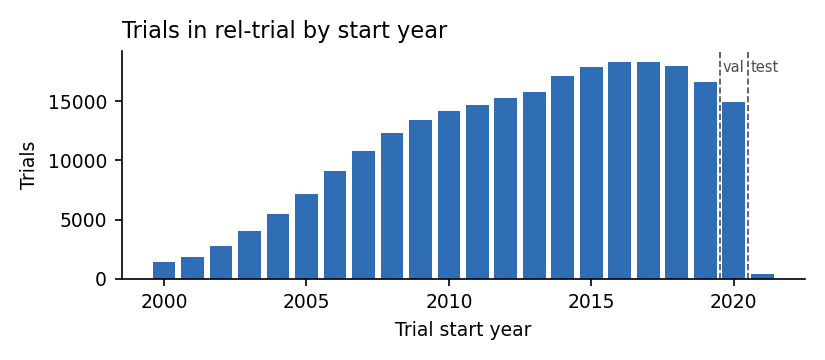

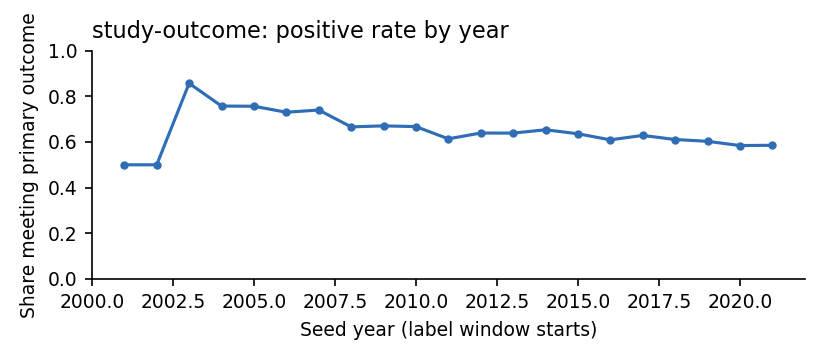

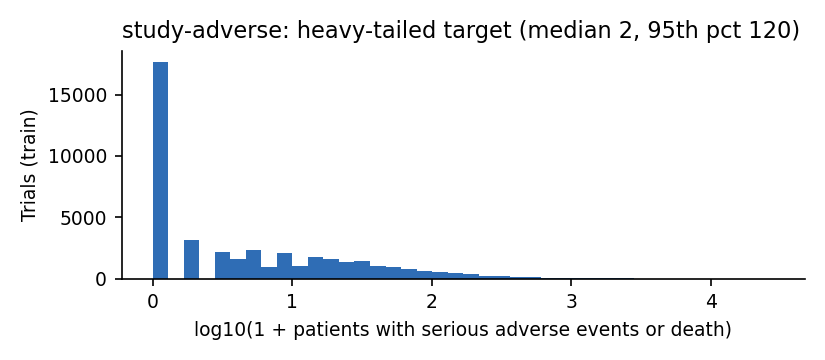

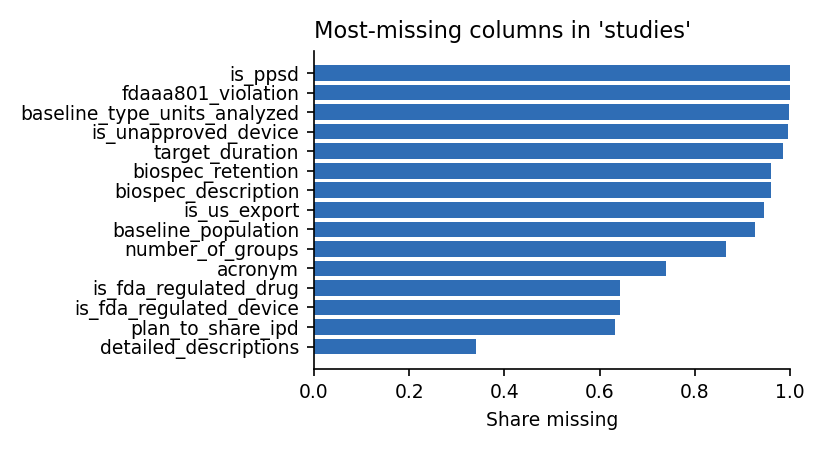

In [10]:
from IPython.display import Image, display
for f in ["trials_per_year", "outcome_rate_by_year", "adverse_distribution", "missingness"]:
    display(Image(f"{RESULTS}/explore/{f}.png", width=650))

## 3. LightGBM baselines
Two feature sets, each tuned with the same budget (20 random-search trials on validation), then trained with 3 seeds:

* `table`: the trial's own row in `studies` plus a TF-IDF/SVD summary of its title;
* `agg`: `table` + one-to-one satellite tables (`designs`, `eligibilities`), counts of linked rows, and each linked sponsor/condition/facility/intervention's history. A row with seed time *t* only sees rows dated ≤ *t* and labels known by *t* (label time + 1 year), the same rule the GNN's sampler applies.

In [11]:
!python scripts/run.py lgbm --features table agg --seeds 0 1 2 --n_trials 20 --results {RESULTS}

Loading rel-trial / study-outcome ...
Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 38 files: 100% 38/38 [00:00<00:00, 1694.63it/s]
Download complete:           |  0.00B            
Reconstruction complete: |          |  0.00B /  0.00B            
Download complete:           |  0.00B            
[study-outcome] building 'table' features ...
  51 features, 11994 train rows (7.2s)
[study-outcome] tuning lgbm_table (20 trials) ...
  trial 01/20: val roc_auc=0.6865 (best 0.6865)
  trial 02/20: val roc_auc=0.6838 (best 0.6865)
  trial 03/20: val roc_auc=0.6832 (best 0.6865)
  trial 04/20: val roc_auc=0.6751 (best 0.6865)
  trial 05/20: val roc_auc=0.6826 (best 0.6865)
  trial 06/20: val roc_auc=0.6751 (best 0.6865)
  trial 07/20: val roc_auc=0.6946 (best 0.6946)
  trial 08/20: val roc_auc=0.6880 (best 0.6946)
  trial 09/20: val roc_auc=0.6908 (best 0.6946)
  trial 10/20: val roc_auc=0.6906 (best 0.6946)
  trial 11/20: val roc_auc=0.6860 (best 0.69

## 4. Relational Deep Learning baseline (hetero GraphSAGE)
Builds the relational entity graph once per task (cached in Drive), then trains 3 seeds with RelBench's reference settings: 2 layers, 128 channels, 128/64 sampled neighbors, 10 epochs, lr 0.005.

If the session runs out of RAM while building the graph, rerun with `--text none` (drops text columns) and note it in the report.

In [24]:
#!python scripts/run.py rdl --text glove --seeds 0 1 2 --save_embeddings --cache_dir {CACHE} --results {RESULTS}
!python scripts/run.py rdl --text none --seeds 0 1 2 --save_embeddings --cache_dir {CACHE} --results {RESULTS}

/usr/local/lib/python3.13/dist-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
Loading rel-trial / study-outcome ...
Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 38 files: 100% 38/38 [00:00<00:00, 1232.12it/s]
Download complete:           |  0.00B            
Download complete:           |  0.00B            
Reconstruction complete: |          |  0.00B /  0.00B            
[study-outcome] building graph (text=none) ...
  seed 0 epoch 01: loss 0.6787  val roc_auc 0.5342
  seed 0 epoch 02: loss 0.6522  val roc_auc 0.5537
  seed 0 epoch 03: loss 0.6475  val roc_auc 0.5906
  seed 0 epoch 04: loss 0.6311  val roc_auc 0.6162
  seed 0 epoch 05: loss 0.6237  val roc_auc 0.6279
  seed 0 epoch 06: loss 0.6198  val roc_auc 0.6085
  seed 0 epoch 07: loss 0.6173  val roc_auc 0.6431
  seed 0 epoch 08: loss 0.6139  val roc_auc 0.6198
  seed 0 epoch 09: 

## 5. Results table
Mean ± 95% CI over seeds; best value per column in bold; RelBench's published single-run numbers for reference.

In [25]:
!python scripts/run.py tables --results {RESULTS}
from IPython.display import Markdown
display(Markdown(open(f"{RESULTS}/tables/main.md").read()))

| Model | Outcome AUROC (val) | Outcome AUROC (test) | Adverse NMAE (val) | Adverse NMAE (test) | Adverse MAE (test) | Seeds |
|---|---|---|---|---|---|---|
| LightGBM (trial table) | 0.689 ± 0.013 | 0.718 ± 0.035 | 0.112 ± 0.001 | 0.106 ± 0.002 | 36.051 ± 0.752 | 3 |
| LightGBM + aggregates | **0.701 ± 0.008** | **0.734 ± 0.015** | **0.106 ± 0.001** | **0.102 ± 0.002** | **34.736 ± 0.691** | 3 |
| RDL (GraphSAGE) | 0.638 ± 0.015 | 0.636 ± 0.008 | 0.145 ± 0.002 | 0.139 ± 0.002 | 47.048 ± 0.783 | 3 |
| *RelBench reference: LightGBM (trial table)* | -- | 0.689 | -- | 0.129 | -- | 1 |
| *RelBench reference: RDL (GraphSAGE)* | -- | 0.669 | -- | 0.129 | -- | 1 |

Mean ± 95% CI over seeds. AUROC: higher is better. NMAE = MAE / train std (RelBench v3's regression metric): lower is better.


| Model | Outcome AUROC (val) | Outcome AUROC (test) | Adverse NMAE (val) | Adverse NMAE (test) | Adverse MAE (test) | Seeds |
|---|---|---|---|---|---|---|
| LightGBM (trial table) | 0.689 ± 0.013 | 0.718 ± 0.035 | 0.112 ± 0.001 | 0.106 ± 0.002 | 36.051 ± 0.752 | 3 |
| LightGBM + aggregates | **0.701 ± 0.008** | **0.734 ± 0.015** | **0.106 ± 0.001** | **0.102 ± 0.002** | **34.736 ± 0.691** | 3 |
| RDL (GraphSAGE) | 0.638 ± 0.015 | 0.636 ± 0.008 | 0.145 ± 0.002 | 0.139 ± 0.002 | 47.048 ± 0.783 | 3 |
| *RelBench reference: LightGBM (trial table)* | -- | 0.689 | -- | 0.129 | -- | 1 |
| *RelBench reference: RDL (GraphSAGE)* | -- | 0.669 | -- | 0.129 | -- | 1 |

Mean ± 95% CI over seeds. AUROC: higher is better. NMAE = MAE / train std (RelBench v3's regression metric): lower is better.


## 6. Package the results
Downloads `milestone_results.zip`. Upload its `explore/` and `tables/` folders to Overleaf (next to `milestone.tex`) and commit them to the repo under `results/`.

In [26]:
import shutil
shutil.make_archive("/content/milestone_results", "zip", RESULTS, ".")
from google.colab import files
files.download("/content/milestone_results.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>